In [1]:
import os, glob, re, csv
import numpy as np
import nibabel as nib
import statsmodels.api as sm
from nilearn import datasets
from nilearn.image import resample_to_img
import pandas as pd
from scipy.stats import ttest_1samp
from nilearn import plotting, datasets
import scipy.stats as stats


In [2]:
# Load the BOLD cleaned image
bold_img = nib.load('/Volumes/Passport/fmriprep/derivatives/pieMan_cleaned/sub-002/func/sub-002_task-pieman_run-1_cleaned_desc-masked_bold.nii.gz')

# Print voxel size (spatial resolution) and TR (temporal resolution)
zooms = bold_img.header.get_zooms()
print(f"Voxel size (mm): {zooms[:3]}")
print(f"TR (s): {zooms[3]}")
print(f"Shape {bold_img.shape}")

Voxel size (mm): (3.0, 3.0, 4.0)
TR (s): 1.5
Shape (65, 77, 49, 160)


In [3]:
# SET MAIN HYPERPARAMETERS
# TRAIT_LABEL = "Contemplating"  

TRAIT_SETS = {
    "all_13": [
        "Open-minded","feeling Affectionate","Attentive","Assertive",
        "feeling Gloomy","feeling Peaceful","Agreeable","Judging",
        "feeling Angry","feeling Bewildered","Impulsive",
        "Self-disciplined","Contemplating"
    ],
    "mental_8": [
        "feeling Affectionate","feeling Gloomy","feeling Peaceful",
        "feeling Angry","feeling Bewildered","Judging",
        "Contemplating","Attentive"
    ],
    "personality_5": [
        "Open-minded","Agreeable","Assertive",
        "Self-disciplined","Impulsive"
    ],
    "trait_9": [
        "Open-minded","feeling Affectionate","Attentive","Assertive",
        "Agreeable","Judging","feeling Angry","Self-disciplined","Contemplating"
    ]
}

# Select model here: choose one key from TRAIT_SETS
model_key = "all_13"   # options: all_13, mental_8, personality_5, drop4_9
traits    = TRAIT_SETS[model_key]

# ALL_TRAIT_LABELS = [
    #"Open-minded","feeling Affectionate","Attentive","Assertive",
    #"feeling Gloomy","feeling Peaceful","Agreeable","Judging",
    #"feeling Angry","feeling Bewildered","Impulsive",
    #"Self-disciplined","Contemplating"
#]
ALL_TRAIT_SAVE_STRS = [t.replace(" ","_").replace("-","_")
                       for t in traits]
# Our 13 trait labels 
# ["Open-minded", "feeling Affectionate", "Attentive", "Assertive", "feeling Gloomy", "feeling Peaceful", "Agreeable", "Judging", "feeling Angry", "feeling Bewildered", "Impulsive", "Self-disciplined", "Contemplating"]

#TRAIT_LABEL_SAVE_STRING = TRAIT_LABEL.replace(" ", "_").replace("-", "_")
STIMULUS_LABEL_SAVE_STRING = "pieman"

In [4]:
# ──────────────────────────────────────────────────────────────
# 0) PATHS & I/O
# ──────────────────────────────────────────────────────────────
root_dir  = "/Volumes/Passport/fmriprep"          # ←  same as in cleaning script
deriv_dir = os.path.join(root_dir, "derivatives") #   (don’t hard-code “subjects” yet)



# output from your behaviour-model RSA
for trait_long, trait_save in zip(traits, ALL_TRAIT_SAVE_STRS):
    rdm_path = os.path.join(
        deriv_dir, "RDMs_behavior",
        f"{STIMULUS_LABEL_SAVE_STRING}_{trait_save}_RDM.npy"
    )
    model_rdm = np.load(rdm_path)

In [5]:
# ──────────────────────────────────────────────────────────────
# 1) SUBJECT / RUN FILTERS  (copy-paste verbatim)  ─────────────
# ──────────────────────────────────────────────────────────────
exclude_subs = {
    "sub-001","sub-021","sub-022","sub-038","sub-056","sub-068","sub-069"
}
exclude_sub_runs = {
    ("sub-002","2"),("sub-003","2"),("sub-004","2"),("sub-005","2"),("sub-006","2"),
    ("sub-008","2"),("sub-010","2"),("sub-011","2"),("sub-012","2"),("sub-013","2"),
    ("sub-014","2"),("sub-015","2"),("sub-016","2")
}
target_subject = None     # e.g. "sub-002" to run a single person


In [6]:
# ----------------------------------------------------------------
# 2)  BUILD SUBJECT LIST  (from cleaned derivatives)  ------------
# ----------------------------------------------------------------
cleaned_root = os.path.join(deriv_dir, f"{STIMULUS_LABEL_SAVE_STRING}_cleaned")
all_subs     = sorted(
    d for d in os.listdir(cleaned_root) if d.startswith("sub-")
)
if target_subject:
    if target_subject not in all_subs:
        raise ValueError(f"{target_subject} not found in {cleaned_root}")
    subjects = [target_subject]
else:
    subjects = [s for s in all_subs if s not in exclude_subs]

print("Subjects to process →", ", ".join(subjects))

Subjects to process → sub-002, sub-003, sub-004, sub-005, sub-006, sub-007, sub-008, sub-009, sub-010, sub-011, sub-012, sub-013, sub-014, sub-015, sub-016, sub-017, sub-018, sub-019, sub-020, sub-023, sub-024, sub-025, sub-026, sub-027, sub-028, sub-029, sub-030, sub-031, sub-032, sub-033, sub-034, sub-035, sub-036, sub-037, sub-039, sub-040, sub-041, sub-042, sub-043, sub-044, sub-045, sub-046, sub-047, sub-048, sub-049, sub-050, sub-051, sub-052, sub-053, sub-054, sub-055, sub-057, sub-058, sub-059, sub-060, sub-061, sub-062, sub-063, sub-064, sub-065, sub-066, sub-067, sub-070, sub-071, sub-072, sub-073, sub-074, sub-075, sub-076, sub-077, sub-078, sub-079, sub-080, sub-081, sub-082


In [7]:
# ──────────────────────────────────────────────────────────────
# 3) FETCH SCHAEFER ATLAS  ─────────────────────────────────────
# ──────────────────────────────────────────────────────────────

# Schaefer parcel/atlas parameters
n_rois = 200
yeo_networks = 17
resolution_mm = 2                   # resolution of your Schaefer atlas (double check!)

schaefer    = datasets.fetch_atlas_schaefer_2018(
                 n_rois=n_rois,
                 yeo_networks=yeo_networks,
                 resolution_mm=resolution_mm
             )
atlas_img   = nib.load(schaefer['maps'])  # default 2mm MNI - but our images 3x3x4 (Pieman and others) OR 2.5^3 (ie., Black and Forgot)

atlas_resampled = resample_to_img(atlas_img, bold_img, interpolation='nearest')
atlas_data     = atlas_resampled.get_fdata()



# Change Schaeffer Labels so 0 is whole brain and 1 corresponds to 1st ROI
labels = schaefer['labels']
# change to string and remove excess
labels = [l.replace(b'17Networks_', b'').decode('utf-8') for l in labels]
# Prepend background label
labels = np.insert(labels, 0, "Background")

In [8]:
# ──────────────────────────────────────────────────────────────
# 4) Run Multiple Regression  ─────────────────────────────────────
# ──────────────────────────────────────────────────────────────

# 1) Load all the single-trait .npy RDMs 
model_rdms = {}
for trait, sstr in zip(traits, ALL_TRAIT_SAVE_STRS):
    filepath = os.path.join(
        deriv_dir, "RDMs_behavior",
        f"{STIMULUS_LABEL_SAVE_STRING}_{sstr}_RDM.npy"
    )
    model_rdms[trait] = np.load(filepath)

# 2) multi-regression RSA 
def rsa_multi(neural_rdm, model_rdms, traits):
    idx = np.tril_indices(neural_rdm.shape[0], k=-1)
    y   = neural_rdm[idx]
    Xs  = [model_rdms[t][idx] for t in traits]
    X   = np.column_stack(Xs)
    X   = sm.add_constant(X)
    res = sm.OLS(y, X).fit()
    print(res)
    print("\n\n")
    print(res.summary())
    betas = res.params[1:]
    f_stat = float(res.fvalue)
    return dict(zip(traits, betas)), f_stat

# 3) run multi-regression for each subject 
def run_multi_for_subject(sub):
    func_dir   = os.path.join(cleaned_root, sub, "func")
    run_pat    = os.path.join(
        func_dir,
        f"{sub}_task-{STIMULUS_LABEL_SAVE_STRING}_run-*_*cleaned_desc-masked_bold.nii.gz"
    )
    single_pat = os.path.join(
        func_dir,
        f"{sub}_task-{STIMULUS_LABEL_SAVE_STRING}_cleaned_desc-masked_bold.nii.gz"
    )
    bold_files = sorted(glob.glob(run_pat)) + sorted(glob.glob(single_pat))
    if not bold_files:
        print(f"⏩ {sub}: no runs"); return

    rows = []
    for bf in bold_files:
        m   = re.search(r"_run-(\d+)_", os.path.basename(bf))
        run = m.group(1) if m else "NA"
        if (sub, run) in exclude_sub_runs: continue

        bold_img  = nib.load(bf)
        bold_data = bold_img.get_fdata()
        atlas_res = resample_to_img(atlas_img, bold_img, interpolation="nearest")
        atlas_dat = atlas_res.get_fdata()

        for parcel_id in range(1, n_rois+1):
            mask = atlas_dat == parcel_id
            if not mask.any(): continue
            neural_rdm = 1 - np.corrcoef(bold_data[mask,:].T).astype(np.float32)
            betas, f_stat = rsa_multi(neural_rdm, model_rdms, traits)
            parcel_label = labels[parcel_id]     # ← NEW column
            # build row: sub, run, parcel, β₁…β₁₃, F_stat
            row = [sub, run, parcel_id, parcel_label] + [betas[t] for t in traits] + [f_stat]
            rows.append(row)

    #4) write out into a new multi_regression folder
    out_base = os.path.join(
        deriv_dir, "RSA_stats",
        STIMULUS_LABEL_SAVE_STRING, "multi_regression"
    )
    os.makedirs(out_base, exist_ok=True)

    header = ["subject","run","parcel_num", "parcel_label"] + ALL_TRAIT_SAVE_STRS + ["F_stat"]
    out_csv = os.path.join(
        out_base,
        f"{sub}_{STIMULUS_LABEL_SAVE_STRING}_multi_parcel_RSA_OLS_{model_key}.csv"
    )
    with open(out_csv, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(header)
        w.writerows(rows)

    print(f"✅ {sub} MULTI-REG CSV → {out_csv}")

# 5) callfor each subject
for sub in subjects:
    run_multi_for_subject(sub)
    # break

print("ALL MULTI-REG DONE 🎉")




                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.008
Model:                            OLS   Adj. R-squared:                  0.007
Method:                 Least Squares   F-statistic:                     8.378
Date:                Thu, 29 May 2025   Prob (F-statistic):           3.67e-17
Time:                        09:32:32   Log-Likelihood:                 675.64
No. Observations:               12720   AIC:                            -1323.
Df Residuals:                   12706   BIC:                            -1219.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.9710      0.006    164.425      

In [9]:
from scipy.stats import ttest_1samp
from statsmodels.stats.multitest import fdrcorrection

# collect all F_stats
records = []
pattern = os.path.join(
    deriv_dir, "RSA_stats", STIMULUS_LABEL_SAVE_STRING,
    "multi_regression", f"*_multi_parcel_RSA_OLS_{model_key}.csv"
)
for fn in glob.glob(pattern):
    df = pd.read_csv(fn, usecols=["subject","run","parcel_num","F_stat"])
    # create one row per entry
    df["unit"] = df["subject"] + "_" + df["run"].astype(str)
    records.append(df)
all_f = pd.concat(records, ignore_index=True)

# group‐level t-test per parcel
group_results = []
for parcel, grp in all_f.groupby("parcel_num"):
    t_stat, p_unc = ttest_1samp(grp["F_stat"], popmean=1, alternative="greater")
    group_results.append((parcel, t_stat, p_unc))

gr = pd.DataFrame(group_results, columns=["parcel_num","t_stat","p_uncorrected"])
# FDR across all parcels
_, p_fdr = fdrcorrection(gr["p_uncorrected"])
gr["p_fdr"] = p_fdr

# add parcel labels
gr["parcel_label"] = labels[1:]  # skip background label

# reorganize columns
gr = gr[["parcel_num","parcel_label","t_stat","p_uncorrected","p_fdr"]]

# save
out_group = os.path.join(
    deriv_dir, "RSA_stats", STIMULUS_LABEL_SAVE_STRING,
    "multi_regression", f"group_F1_stats_with_FDR_OLS_{model_key}.csv"
)
gr.to_csv(out_group, index=False)
print(f"✅ Saved group‐level F‐test results → {out_group}")

✅ Saved group‐level F‐test results → /Volumes/Passport/fmriprep/derivatives/RSA_stats/pieman/multi_regression/group_F1_stats_with_FDR_OLS_all_13.csv


✅ Saved thresholded t-map → /Volumes/Passport/fmriprep/derivatives/RSA_stats/pieman/multi_regression/200parcel_t_map_OLS_all_13.nii.gz


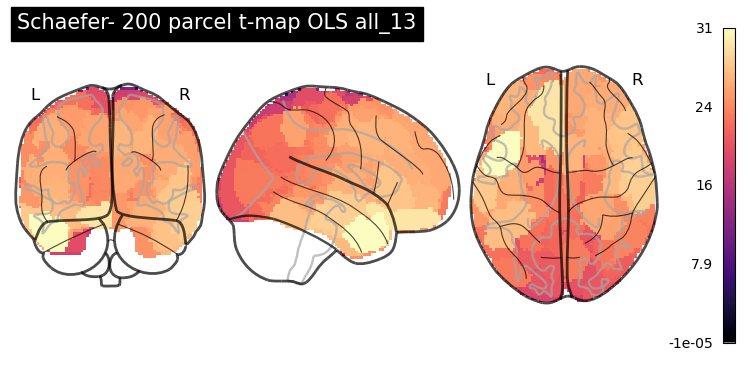

In [10]:
# ─── PARAMETERS ───────────────────────────────────────────────────────────
n_rois = 200
yeo_networks = 17
resolution_mm = 2
# fdr_alpha = 0.05     # threshold for p_fdr

# input CSV from group‐level t-test against F=1
group_csv = f"/Volumes/Passport/fmriprep/derivatives/RSA_stats/pieman/multi_regression/group_F1_stats_with_FDR_OLS_{model_key}.csv"

# output map filename
out_nii  = f"{n_rois}_parcel_t_map_OLS_{model_key}.nii.gz"

# ─── 1) LOAD & THRESHOLD ─────────────────────────────────────────────────
gr = pd.read_csv(group_csv)
# grab the full list of t‐stats in parcel order
t_values = gr.sort_values("parcel_num")["t_stat"].tolist()
# threshold down to only the significant parcels
# thr = gr[gr["p_fdr"] < fdr_alpha]

# ─── 2) FETCH THE SCHAEFER ATLAS ─────────────────────────────────────
schaefer   = datasets.fetch_atlas_schaefer_2018(
    n_rois=n_rois,
    yeo_networks=yeo_networks,
    resolution_mm=resolution_mm
)
atlas_img  = nib.load(schaefer["maps"])
atlas_data = atlas_img.get_fdata().astype(int)

# sanity check
assert atlas_data.max() == n_rois

# ─── 3) BUILD THE 3D T-STAT MAP ──────────────────────────────────────────
t_map = np.zeros_like(atlas_data, dtype=float)
for _, row in gr.iterrows():
    pid    = int(row["parcel_num"])
    tstat  = float(row["t_stat"])
    t_map[atlas_data == pid] = tstat

# ─── 4) SAVE OUT NIfTI ───────────────────────────────────────────────────
out_dir = os.path.join(
    deriv_dir,
    "RSA_stats",
    STIMULUS_LABEL_SAVE_STRING,   # no {…}
    "multi_regression",           # no {…}
)
os.makedirs(out_dir, exist_ok=True)

out_nii = os.path.join(
    out_dir,
    f"{n_rois}parcel_t_map_OLS_{model_key}.nii.gz"
)
new_img = nib.Nifti1Image(t_map, atlas_img.affine, atlas_img.header)
nib.save(new_img, out_nii)
print("✅ Saved thresholded t-map →", out_nii)

# ─── 5) PLOT (GLASS BRAIN) ────────────────────────────────────────────────
plotting.plot_glass_brain(
    out_nii,
    # threshold =5.0,      # set t threshold for more or less conservative display
    cmap="magma",
    colorbar=True,
    title=f"Schaefer- {n_rois} parcel t-map OLS {model_key}",
)
plotting.show() 